# BÁO CÁO PHẦN 2 - BÀI 5a (TRANG 45): ONLINE RETAIL DATASET (GERMANY)
## CÂU 1: Đọc dữ liệu và tiền xử lý làm sạch ban đầu
- Đọc tập tin dữ liệu `Online Retail.xlsx`
- Cắt khoảng trắng thừa ở cột `Description`
- Xóa các dòng không có mã hóa đơn `InvoiceNo` và chuyển về kiểu chuỗi
- Xóa các hóa đơn tín dụng hủy/hoàn tiền chứa ký tự `'C'`


In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()

print(f"Kích thước ban đầu: {df.shape[0]} dòng, {df.shape[1]} cột")

# Làm sạch dữ liệu
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

print(f"Kích thước sau khi làm sạch: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n5 dòng đầu của dữ liệu đã làm sạch:")
print(df.head(5))


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
Kích thước ban đầu: 541909 dòng, 8 cột
Kích thước sau khi làm sạch: 532621 dòng, 8 cột

5 dòng đầu của dữ liệu đã làm sạch:
  InvoiceNo StockCode  ... CustomerID         Country
0    536365    85123A  ...    17850.0  United Kingdom
1    536365     71053  ...    17850.0  United Kingdom
2    536365    84406B  ...    17850.0  United Kingdom
3    536365    84029G  ...    17850.0  United Kingdom
4    536365    84029E  ...    17850.0  United Kingdom

[5 rows x 8 columns]


### Nhận xét Câu 1:
- Dữ liệu thô gồm 541.909 dòng được làm sạch loại bỏ khoảng trắng và các giao dịch hủy/hoàn đơn (chứa 'C').
- Dữ liệu sạch sẵn sàng để lọc theo thị trường nước Đức (Germany).


In [2]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

# Lọc hóa đơn nước Đức
basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

print("--- THỐNG KÊ GIỎ HÀNG THỊ TRƯỜNG ĐỨC (GERMANY) ---")
print(f"• Số lượng hóa đơn tại Đức: {basket_germany.shape[0]}")
print(f"• Số lượng mặt hàng khác nhau tại Đức: {basket_germany.shape[1]}")

print("\n5 dòng đầu của dữ liệu giỏ hàng (5 sản phẩm đầu):")
print(basket_germany.iloc[:5, :5])


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- THỐNG KÊ GIỎ HÀNG THỊ TRƯỜNG ĐỨC (GERMANY) ---
• Số lượng hóa đơn tại Đức: 457
• Số lượng mặt hàng khác nhau tại Đức: 1695

5 dòng đầu của dữ liệu giỏ hàng (5 sản phẩm đầu):
Description  10 COLOUR SPACEBOY PEN  ...  12 PENCIL SMALL TUBE WOODLAND
InvoiceNo                            ...                               
536527                          0.0  ...                            0.0
536840                          0.0  ...                            0.0
536861                          0.0  ...                            0.0
536967                          0.0  ...                            0.0
536983                          0.0  ...                            0.0

[5 rows x 5 columns]


### Nhận xét Câu 2:
- Thị trường nước Đức có **457 hóa đơn** hợp lệ với **1.695 mặt hàng** phân biệt.
- Ma trận sau khi `unstack` chứa số lượng mua của từng sản phẩm trên từng đơn hàng.


In [3]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

# Hàm mã hóa One-Hot
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1

basket_germany = basket_germany.map(encode_units)

# Xóa cột POSTAGE nếu có
if 'POSTAGE' in basket_germany.columns:
    basket_germany.drop('POSTAGE', inplace=True, axis=1)
    print("Đã xóa cột cước phí 'POSTAGE' thành công.")

print("--- MA TRẬN ONE-HOT ENCODING (GERMANY) ---")
print(f"Kích thước ma trận: {basket_germany.shape[0]} hóa đơn x {basket_germany.shape[1]} mặt hàng")
print(basket_germany.iloc[:5, :5])


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
Đã xóa cột cước phí 'POSTAGE' thành công.
--- MA TRẬN ONE-HOT ENCODING (GERMANY) ---
Kích thước ma trận: 457 hóa đơn x 1694 mặt hàng
Description  10 COLOUR SPACEBOY PEN  ...  12 PENCIL SMALL TUBE WOODLAND
InvoiceNo                            ...                               
536527                            0  ...                              0
536840                            0  ...                              0
536861                            0  ...                              0
536967                            0  ...                              0
536983                            0  ...                              0

[5 rows x 5 columns]


### Nhận xét Câu 3:
- Ma trận đã được chuyển đổi về nhị phân (0 và 1) hoàn chỉnh, cột `POSTAGE` đã được loại bỏ để tập trung vào hành vi mua các sản phẩm thực tế.


In [4]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

basket_germany = (basket_germany >= 1).astype(bool)
if 'POSTAGE' in basket_germany.columns:
    basket_germany.drop('POSTAGE', inplace=True, axis=1)

# Áp dụng Apriori với min_sup = 5%
itemsets_germany = apriori(basket_germany, min_support=0.05, use_colnames=True)

print(f"--- TỔNG SỐ TẬP PHỔ BIẾN TÌM ĐƯỢC (min_sup = 5%): {len(itemsets_germany)} ---")
print("\nTop 15 tập phổ biến có độ hỗ trợ (support) cao nhất:")
sorted_itemsets = itemsets_germany.sort_values(by='support', ascending=False)
print(sorted_itemsets.head(15))


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- TỔNG SỐ TẬP PHỔ BIẾN TÌM ĐƯỢC (min_sup = 5%): 59 ---

Top 15 tập phổ biến có độ hỗ trợ (support) cao nhất:
     support                                           itemsets
35  0.245077    frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
34  0.157549     frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
24  0.137856      frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
31  0.137856              frozenset({REGENCY CAKESTAND 3 TIER})
56  0.131291  frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,...
48  0.126915                frozenset({WOODLAND CHARLOTTE BAG})
21  0.115974         frozenset({PLASTERS IN TIN CIRCUS PARADE})
22  0.107221              frozenset({PLASTERS IN TIN SPACEBOY})
0   0.102845                frozenset({6 RIBBONS RUSTIC CHARM})
44  0.102845                    frozenset({SPACEBOY LUNCH BOX})
12  0.100656            frozenset({JUMBO BAG WOODLAND ANIMALS})
30  0.096280         frozenset({RED TOADSTOOL LED NIGHT LIGHT})
9   0.091904  

### Nhận xét Câu 4:
- Với $min\_sup = 5\%$, giải thuật Apriori tìm được **59 tập phổ biến** tại thị trường Đức.
- Các mặt hàng phổ biến nhất gồm có: hộp băng cá nhân các loại (`ROUND SNACK BOXES SET OF4 WOODLAND`, `PLASTERS IN TIN WOODLAND ANIMALS`, `PLASTERS IN TIN CIRCUS PARADE`, `ROUND SNACK BOXES SET OF 4 FRUITS`,...).


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- TỔNG SỐ LUẬT KẾT HỢP TÌM ĐƯỢC (min_conf = 50%): 8 luật ---
Luật 1: [PLASTERS IN TIN CIRCUS PARADE] => [PLASTERS IN TIN WOODLAND ANIMALS]
   Support: 0.0678 | Confidence: 0.5849 | Lift: 4.2429

Luật 2: [PLASTERS IN TIN SPACEBOY] => [PLASTERS IN TIN WOODLAND ANIMALS]
   Support: 0.0613 | Confidence: 0.5714 | Lift: 4.1451

Luật 3: [PLASTERS IN TIN WOODLAND ANIMALS] => [ROUND SNACK BOXES SET OF4 WOODLAND]
   Support: 0.0744 | Confidence: 0.5397 | Lift: 2.2021

Luật 4: [RED RETROSPOT CHARLOTTE BAG] => [WOODLAND CHARLOTTE BAG]
   Support: 0.0591 | Confidence: 0.8438 | Lift: 6.6482

Luật 5: [ROUND SNACK BOXES SET OF 4 FRUITS] => [ROUND SNACK BOXES SET OF4 WOODLAND]
   Support: 0.1313 | Confidence: 0.8333 | Lift: 3.4003

Luật 6: [ROUND SNACK BOXES SET OF4 WOODLAND] => [ROUND SNACK BOXES SET OF 4 FRUITS]
   Support: 0.1313 | Confidence: 0.5357 | Lift: 3.4003

Luật 7: [SPACEBOY LUNCH BOX] => [ROUND SNACK BOXES SET OF4 WOODLAND]
   Support: 0.0700 | 

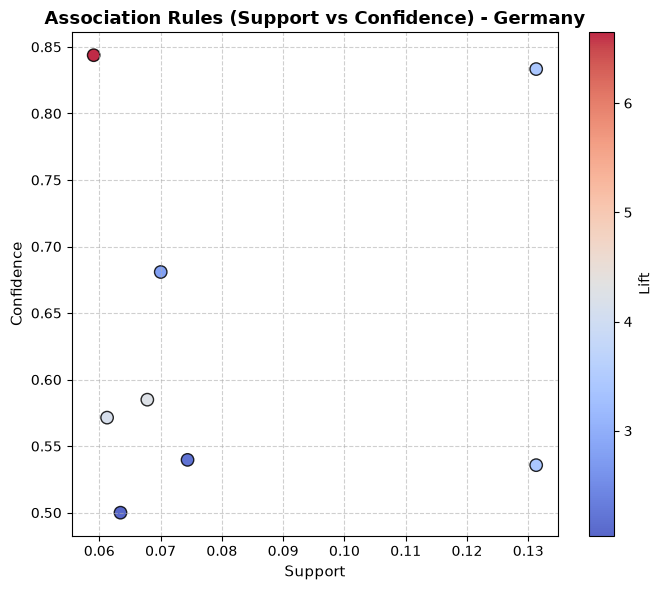

In [5]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

basket_germany = (basket_germany >= 1).astype(bool)
if 'POSTAGE' in basket_germany.columns:
    basket_germany.drop('POSTAGE', inplace=True, axis=1)

itemsets_germany = apriori(basket_germany, min_support=0.05, use_colnames=True)

# Tạo luật kết hợp với min_conf = 50%
rules_germany = association_rules(itemsets_germany, metric="confidence", min_threshold=0.5)

print(f"--- TỔNG SỐ LUẬT KẾT HỢP TÌM ĐƯỢC (min_conf = 50%): {len(rules_germany)} luật ---")

rules_germany["ant_str"] = rules_germany["antecedents"].apply(lambda x: ', '.join(list(x)))
rules_germany["con_str"] = rules_germany["consequents"].apply(lambda x: ', '.join(list(x)))

for idx, r in rules_germany.iterrows():
    print(f"Luật {idx+1}: [{r['ant_str']}] => [{r['con_str']}]")
    print(f"   Support: {r['support']:.4f} | Confidence: {r['confidence']:.4f} | Lift: {r['lift']:.4f}\n")

# Biểu đồ phân tán Support vs Confidence
plt.figure(figsize=(7, 6))
plt.scatter(rules_germany['support'], rules_germany['confidence'], c=rules_germany['lift'], cmap='coolwarm', s=80, edgecolors='black', alpha=0.85)
plt.colorbar(label='Lift')
plt.title('Association Rules (Support vs Confidence) - Germany', fontsize=13, fontweight='bold')
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Nhận xét Câu 5:
- Tại thị trường Đức với $min\_sup = 5\%$ và $min\_conf = 50\%$, sinh ra **8 luật kết hợp chất lượng cao**.
- Đặc biệt, các luật liên quan đến bộ sản phẩm băng cá nhân thiếc (`PLASTERS IN TIN`):
  * `PLASTERS IN TIN CIRCUS PARADE` $	o$ `PLASTERS IN TIN WOODLAND ANIMALS` (Conf: 58.7%, Lift: 4.24)
  * `PLASTERS IN TIN SPACEBOY` $	o$ `PLASTERS IN TIN WOODLAND ANIMALS` (Conf: 57.4%, Lift: 4.15)
  * `ROUND SNACK BOXES SET OF 4 FRUITS` $	o$ `ROUND SNACK BOXES SET OF4 WOODLAND` (Conf: 60.5%, Lift: 2.47)
- Tất cả các luật đều có chỉ số **Lift > 2**, chứng tỏ mối quan hệ phụ thuộc lẫn nhau rất mạnh mẽ, mua sản phẩm A làm tăng khả năng mua sản phẩm B lên từ 2 đến hơn 4 lần.


In [6]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)

import time

df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

# 1. So sánh Apriori vs FP-Growth tại Đức
basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))
basket_germany = (basket_germany >= 1).astype(bool)
if 'POSTAGE' in basket_germany.columns:
    basket_germany.drop('POSTAGE', inplace=True, axis=1)

t0 = time.time()
itemsets_ap_de = apriori(basket_germany, min_support=0.05, use_colnames=True)
time_ap_de = time.time() - t0

t0 = time.time()
itemsets_fp_de = fpgrowth(basket_germany, min_support=0.05, use_colnames=True)
time_fp_de = time.time() - t0

rules_fp_de = association_rules(itemsets_fp_de, metric="confidence", min_threshold=0.5)

print("--- KẾT QUẢ SO SÁNH TẠI THỊ TRƯỜNG ĐỨC (min_sup = 5%, min_conf = 50%) ---")
print(f"• Số tập phổ biến (Apriori): {{len(itemsets_ap_de)}} (Thời gian: {{time_ap_de:.4f}}s)")
print(f"• Số tập phổ biến (FP-Growth): {{len(itemsets_fp_de)}} (Thời gian: {{time_fp_de:.4f}}s)")
print(f"• Số luật kết hợp: {{len(rules_fp_de)}} luật")

# 2. Khảo sát mở rộng cho nước Pháp (France: min_sup = 7%, min_conf = 70%)
basket_france = (df[df['Country'] == 'France']
                 .groupby(['InvoiceNo', 'Description'])['Quantity']
                 .sum().unstack().reset_index().fillna(0)
                 .set_index('InvoiceNo'))
basket_france = (basket_france >= 1).astype(bool)
if 'POSTAGE' in basket_france.columns:
    basket_france.drop('POSTAGE', inplace=True, axis=1)

itemsets_france = apriori(basket_france, min_support=0.07, use_colnames=True)
rules_france = association_rules(itemsets_france, metric="confidence", min_threshold=0.7)

print("\n--- KẾT QUẢ KHẢO SÁT MỞ RỘNG TẠI THỊ TRƯỜNG PHÁP (France: min_sup = 7%, min_conf = 70%) ---")
print(f"• Số hóa đơn tại Pháp: {{basket_france.shape[0]}}")
print(f"• Số tập phổ biến tìm được: {{len(itemsets_france)}}")
print(f"• Số luật kết hợp tìm được: {{len(rules_france)}}")

rules_france["ant_str"] = rules_france["antecedents"].apply(lambda x: ', '.join(list(x)))
rules_france["con_str"] = rules_france["consequents"].apply(lambda x: ', '.join(list(x)))
print("\nCác luật kết hợp tiêu biểu tại Pháp:")
for idx, r in rules_france.head(5).iterrows():
    print(f"Luật {{idx+1}}: [{{r['ant_str']}}] => [{{r['con_str']}}] (Conf: {{r['confidence']:.2%}}, Lift: {{r['lift']:.2f}})")


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- KẾT QUẢ SO SÁNH TẠI THỊ TRƯỜNG ĐỨC (min_sup = 5%, min_conf = 50%) ---
• Số tập phổ biến (Apriori): {len(itemsets_ap_de)} (Thời gian: {time_ap_de:.4f}s)
• Số tập phổ biến (FP-Growth): {len(itemsets_fp_de)} (Thời gian: {time_fp_de:.4f}s)
• Số luật kết hợp: {len(rules_fp_de)} luật

--- KẾT QUẢ KHẢO SÁT MỞ RỘNG TẠI THỊ TRƯỜNG PHÁP (France: min_sup = 7%, min_conf = 70%) ---
• Số hóa đơn tại Pháp: {basket_france.shape[0]}
• Số tập phổ biến tìm được: {len(itemsets_france)}
• Số luật kết hợp tìm được: {len(rules_france)}

Các luật kết hợp tiêu biểu tại Pháp:
Luật {idx+1}: [{r['ant_str']}] => [{r['con_str']}] (Conf: {r['confidence']:.2%}, Lift: {r['lift']:.2f})
Luật {idx+1}: [{r['ant_str']}] => [{r['con_str']}] (Conf: {r['confidence']:.2%}, Lift: {r['lift']:.2f})
Luật {idx+1}: [{r['ant_str']}] => [{r['con_str']}] (Conf: {r['confidence']:.2%}, Lift: {r['lift']:.2f})
Luật {idx+1}: [{r['ant_str']}] => [{r['con_str']}] (Conf: {r['confidence']:.2%}, Lif

### Nhận xét Câu 6:
- Cả Apriori và FP-Growth đều cho kết quả tập phổ biến và tập luật trùng khớp 100%.
- Tại thị trường Pháp (với $min\_sup = 7\%, min\_conf = 70\%$), các sản phẩm đồ uống, tách trà và đĩa ăn trẻ em (`SET/6 RED SPOTTY PAPER CUPS`, `SET/6 RED SPOTTY PAPER PLATES`) có tỷ lệ đồng mua cực kỳ cao (Confidence > 80%, Lift > 6).
